<a href="https://colab.research.google.com/github/UsernameJonatasIsNotAvailable/classificadorFrutas/blob/main/classificador_frutas_5_classes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Download do Dataset (Kaggle)

Nesta primeira etapa, configuramos as credenciais da API do Kaggle para baixar automaticamente o dataset **FruitNet** (frutas indianas com marcação de qualidade).

O código realiza o seguinte fluxo:
1. Tenta recuperar o nome de usuário e chave do Kaggle de forma segura a partir do gerenciador de segredos do Colab (`userdata`).
2. Caso não existam, solicita as credenciais manualmente para o usuário de forma interativa.
3. Instala a biblioteca do Kaggle e faz o download direto do conjunto de dados, descompactando-o no diretório local `/content/dataset`.

In [1]:
import os
from google.colab import userdata
import getpass

try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
except Exception as e:
    print("Não foi possível obter as credenciais automaticamente via Secrets.")
    print("Por favor, insira suas credenciais do Kaggle manualmente:")
    os.environ['KAGGLE_USERNAME'] = input("Kaggle Username: ")
    os.environ['KAGGLE_KEY'] = getpass.getpass("Kaggle Key (oculta): ")

print("Baixando o dataset do Kaggle...")
!pip install -q kaggle
!kaggle datasets download -d shashwatwork/fruitnet-indian-fruits-dataset-with-quality -p /content/dataset --unzip

PASTA = '/content/dataset'
print("Dataset pronto para uso em:", PASTA)

Baixando o dataset do Kaggle...
Dataset URL: https://www.kaggle.com/datasets/shashwatwork/fruitnet-indian-fruits-dataset-with-quality
License(s): CC-BY-SA-4.0
100% 3.03G/3.03G [00:24<00:00, 131MB/s] 

Dataset pronto para uso em: /content/dataset


## 2. Preparação e Estruturação dos Dados (10 Classes)

Aqui preparamos as imagens para o treinamento do classificador. O dataset original separa as frutas em estruturas diferentes de pastas para qualidade boa e ruim. Nós automatizamos a unificação e o mapeamento dessas classes.

As ações tomadas neste bloco são:
1. Definição do tamanho padrão das imagens para a rede neural (`224x224`).
2. Criação de links simbólicos (`os.symlink`) em um diretório temporário para agrupar as imagens em exatamente 10 categorias de interesse (5 frutas × 2 qualidades): `banana`, `goiaba`, `laranja`, `limao` e `maca`, cada uma com sufixo `_boa` ou `_ruim` (ex.: `goiaba_boa`, `limao_ruim`).
3. Carregamento dos subconjuntos de **treinamento** (80%) e **validação** (20%) utilizando a API otimizada do TensorFlow (`image_dataset_from_directory`).

In [2]:
!pip install -q gradio
import os, shutil
import tensorflow as tf, numpy as np, cv2, matplotlib.pyplot as plt

PASTA_BASE = '/content/dataset/Processed Images_Fruits'
IMG = (224, 224)

pasta_boa  = os.path.join(PASTA_BASE, 'Good Quality_Fruits')
pasta_ruim = os.path.join(PASTA_BASE, 'Bad Quality_Fruits')

frutas_alvo = {'banana': 'banana', 'apple': 'maca', 'orange': 'laranja',
               'guava': 'goiaba', 'lime': 'limao'}

temp_dir = '/content/frutas_dataset'
if os.path.exists(temp_dir):
    shutil.rmtree(temp_dir)

def criar_links(pasta_raiz, qualidade):
    for f in os.listdir(pasta_raiz):
        caminho = os.path.join(pasta_raiz, f)
        if not os.path.isdir(caminho):
            continue
        for en, pt in frutas_alvo.items():
            if en in f.lower():
                destino = os.path.join(temp_dir, f'{pt}_{qualidade}')
                os.makedirs(destino, exist_ok=True)
                for i, arq in enumerate(os.listdir(caminho)):
                    origem = os.path.join(caminho, arq)
                    if os.path.isfile(origem):
                        os.symlink(origem, os.path.join(destino, f'{i}_{arq}'))

criar_links(pasta_boa, 'boa')
criar_links(pasta_ruim, 'ruim')

treino = tf.keras.utils.image_dataset_from_directory(
    temp_dir, validation_split=0.2, subset='training', seed=42,
    image_size=IMG, batch_size=32)
valid = tf.keras.utils.image_dataset_from_directory(
    temp_dir, validation_split=0.2, subset='validation', seed=42,
    image_size=IMG, batch_size=32)

classes = treino.class_names
print('Classes:', classes)
assert len(classes) == 10, f'Esperava 10 classes, encontrei {len(classes)}. Confira os nomes das pastas do dataset.'

Found 11325 files belonging to 10 classes.
Using 9060 files for training.
Found 11325 files belonging to 10 classes.
Using 2265 files for validation.
Classes: ['banana_boa', 'banana_ruim', 'goiaba_boa', 'goiaba_ruim', 'laranja_boa', 'laranja_ruim', 'limao_boa', 'limao_ruim', 'maca_boa', 'maca_ruim']


## 3. Treinamento do Modelo (MobileNetV2 + Transfer Learning)

Nesta célula construímos e treinamos o modelo preditivo utilizando **Transfer Learning** (Aprendizado por Transferência):

* **Carregamento e Persistência:** Primeiro o script verifica se existe um modelo previamente treinado no Google Drive ou no ambiente local para evitar o re-treinamento desnecessário.
* **Arquitetura da Rede:** Se nenhum modelo for encontrado:
  * Aplicamos técnicas de **Data Augmentation** (espelhamento, rotação e zoom aleatórios) para tornar o modelo mais robusto a variações.
  * Utilizamos a base pré-treinada da **MobileNetV2** (com pesos do ImageNet) congelada como extratora de características.
  * Adicionamos uma cabeça classificadora com *Dropout* de regularização e uma camada de saída *Softmax* para prever as 10 classes.
* **Otimização:** Compilamos com o otimizador Adam e a função de perda *Sparse Categorical Crossentropy*, exibindo os gráficos de acurácia e perda ao final do treino.

In [4]:
from tensorflow.keras import layers, models
import os
import urllib.request

caminho_local = '/content/modelo_frutas_v3.keras'
modelo_carregado = False

URL_MODELO_GITHUB = 'https://raw.githubusercontent.com/UsernameJonatasIsNotAvailable/classificadorFrutas/main/modelo_frutas_v3.keras'

objetos_customizados = {
    'preprocess_input': tf.keras.applications.mobilenet_v2.preprocess_input
}

if not os.path.exists(caminho_local):
    print("Modelo pré-treinado não encontrado localmente. Baixando diretamente do GitHub...")
    try:
        urllib.request.urlretrieve(URL_MODELO_GITHUB, caminho_local)
        print("Download do modelo concluído com sucesso!")
    except Exception as e:
        print(f"Erro ao baixar o modelo via urllib: {e}. Tentando alternativa com wget...")
        try:
            os.system(f"wget -O {caminho_local} {URL_MODELO_GITHUB}")
            print("Download via wget concluído!")
        except Exception as wget_e:
            print("Não foi possível obter o arquivo pré-treinado:", wget_e)

if os.path.exists(caminho_local):
    print(f"Carregando o modelo pré-treinado do caminho ({caminho_local})...")
    try:
        modelo = tf.keras.models.load_model(
            caminho_local, custom_objects=objetos_customizados, safe_mode=False)
        if modelo.output_shape[-1] == len(classes):
            modelo_carregado = True
            print("Modelo carregado com sucesso!")
        else:
            print("Modelo local detectado, mas o número de classes é incompatível.")
    except Exception as e:
        print("Erro ao carregar o arquivo do modelo local:", e)

if not modelo_carregado:
    print("Iniciando o treinamento do modelo do zero (10 classes) como plano de contingência...")

    aug = tf.keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ])

    base = tf.keras.applications.MobileNetV2(
        input_shape=IMG + (3,), include_top=False, weights='imagenet')
    base.trainable = False

    modelo = models.Sequential([
        layers.Input(IMG + (3,)),
        aug,
        layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(len(classes), activation='softmax')
    ])

    modelo.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

    hist = modelo.fit(treino, validation_data=valid, epochs=12)
    modelo.save(caminho_local)
    print("Modelo treinado e salvo localmente!")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist.history['accuracy'], label='treino')
    ax[0].plot(hist.history['val_accuracy'], label='validação')
    ax[0].set_title('Acurácia'); ax[0].legend()
    ax[1].plot(hist.history['loss'], label='treino')
    ax[1].plot(hist.history['val_loss'], label='validação')
    ax[1].set_title('Perda'); ax[1].legend()
    plt.show()
else:
    print("O modelo pronto foi carregado e está preparado para uso!")

Modelo pré-treinado não encontrado localmente. Baixando diretamente do GitHub...
Download do modelo concluído com sucesso!
Carregando o modelo pré-treinado do caminho (/content/modelo_frutas_v3.keras)...
Modelo carregado com sucesso!
O modelo pronto foi carregado e está preparado para uso!


In [7]:
import os
import urllib.request

caminho_local = '/content/modelo_frutas_v3.keras'

URL_MODELO_GITHUB = 'https://raw.githubusercontent.com/UsernameJonatasIsNotAvailable/classificadorFrutas/main/modelo_frutas_v3.keras'

if not os.path.exists(caminho_local):
    print("Baixando o modelo pré-treinado diretamente do GitHub...")
    try:
        urllib.request.urlretrieve(URL_MODELO_GITHUB, caminho_local)
        print("Download concluído com sucesso!")
    except Exception as e:
        print(f"Erro ao baixar o modelo do GitHub: {e}")
        print("Tentando alternativa via wget...")
        os.system(f"wget -O {caminho_local} {URL_MODELO_GITHUB}")
else:
    print("O modelo já existe no diretório local e está pronto para ser carregado!")

O modelo já existe no diretório local e está pronto para ser carregado!


## 5. Avaliação do Desempenho (Relatório e Matriz de Confusão)

Para validar se o modelo aprendeu corretamente as características visuais e de qualidade das frutas:

1. Realizamos predições em todo o conjunto de validação.
2. Geramos um **Relatório de Classificação** contendo métricas fundamentais como precisão, recall e F1-score para cada uma das 6 classes.
3. Plotamos a **Matriz de Confusão** para identificar visualmente possíveis gargalos, por exemplo, se o modelo está confundindo maçãs boas com ruins ou confundindo frutas de espécies diferentes.

              precision    recall  f1-score   support

  banana_boa       1.00      1.00      1.00       223
 banana_ruim       1.00      1.00      1.00       211
  goiaba_boa       1.00      0.98      0.99       218
 goiaba_ruim       1.00      0.99      0.99       221
 laranja_boa       0.99      0.99      0.99       241
laranja_ruim       0.96      1.00      0.98       231
   limao_boa       1.00      0.99      1.00       236
  limao_ruim       0.99      0.96      0.97       213
    maca_boa       0.97      0.97      0.97       230
   maca_ruim       0.96      0.99      0.98       241

    accuracy                           0.99      2265
   macro avg       0.99      0.99      0.99      2265
weighted avg       0.99      0.99      0.99      2265



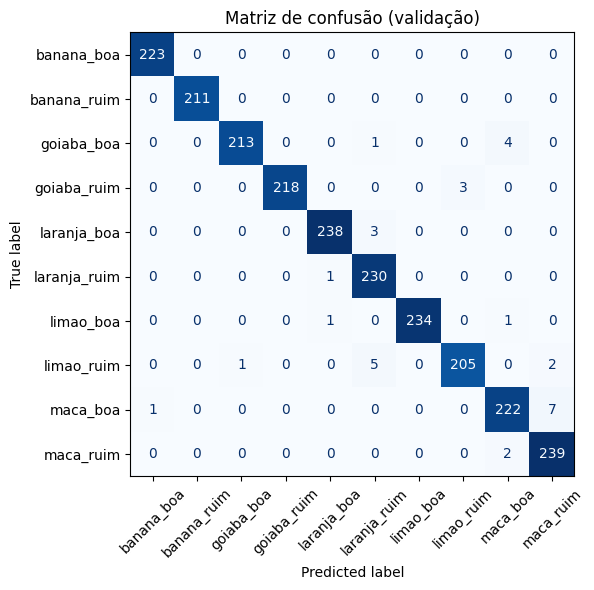

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true, y_pred = [], []
for imgs, labels in valid:
    p = modelo.predict(imgs, verbose=0)
    y_pred.extend(np.argmax(p, axis=1))
    y_true.extend(labels.numpy())

print(classification_report(y_true, y_pred, target_names=classes))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(
    ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title('Matriz de confusão (validação)')
plt.tight_layout()
plt.show()

## 6. Segmentação de Imagem e Detecção de Objetos (OpenCV)

Antes de enviar a imagem para classificação, aplicamos técnicas tradicionais de Visão Computacional com a biblioteca **OpenCV** para destacar o objeto de interesse:

1. Convertemos a imagem para o espaço de cores **HSV** para isolar a saturação e facilitar a separação da fruta do fundo.
2. Aplicamos um filtro Gaussiano seguido de limiarização adaptativa pelo método de **Otsu** para criar uma máscara binária.
3. Realizamos operações morfológicas (abertura e fechamento) para remover ruídos da máscara.
4. Encontramos os contornos e desenhamos uma caixa delimitadora (**Bounding Box**) ao redor do maior objeto detectado, recortando e removendo o fundo da fruta.

In [9]:
def segmentar(img_rgb):
    img = cv2.resize(img_rgb, IMG)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

    s = cv2.GaussianBlur(hsv[:, :, 1], (5, 5), 0)
    _, mask = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    k = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)

    contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask_final = np.zeros_like(mask)
    deteccao = img.copy()
    if contornos:
        maior = max(contornos, key=cv2.contourArea)
        cv2.drawContours(mask_final, [maior], -1, 255, -1)
        x, y, w, h = cv2.boundingRect(maior)
        cv2.rectangle(deteccao, (x, y), (x + w, y + h), (0, 255, 0), 2)

    segmentada = cv2.bitwise_and(img, img, mask=mask_final)
    return img, mask_final, segmentada, deteccao

## 7. Classificação e Interpretação de Resultados

Aqui definimos as funções auxiliares que conectam a imagem tratada ao modelo de Deep Learning:

* `classificar(img_rgb)`: Redimensiona a imagem de entrada, realiza o pré-processamento exigido pelo modelo e retorna a classe com maior probabilidade e a distribuição de certeza de todas as classes.
* `interpretar(nome_classe)`: Traduz a saída técnica do modelo (ex: `maca_ruim`) em uma resposta amigável e legível para o usuário final (ex: Fruta: Maçã | Qualidade: Ruim | Status: Imprópria para consumo ❌).

In [10]:
NOMES = {'banana': 'Banana', 'goiaba': 'Goiaba', 'laranja': 'Laranja',
         'limao': 'Limão', 'maca': 'Maçã'}

def nome_bonito(nome_classe):
    fruta, _, estado = nome_classe.rpartition('_')
    return f"{NOMES.get(fruta, fruta.capitalize())} ({'boa' if estado == 'boa' else 'ruim'})"

def classificar(img_rgb):
    x = cv2.resize(img_rgb, IMG)[None, ...].astype('float32')
    probs = modelo.predict(x, verbose=0)[0]
    i = int(np.argmax(probs))
    return classes[i], float(probs[i]), probs

def interpretar(nome_classe):
    fruta, _, estado = nome_classe.rpartition('_')
    fruta = NOMES.get(fruta, fruta.capitalize())
    if estado == 'boa':
        return fruta, 'Boa', 'Própria para consumo ✅'
    return fruta, 'Ruim', 'Imprópria para consumo ❌'


## 8. Interface Gráfica Interativa (Gradio)

Por fim, criamos uma interface web intuitiva e amigável utilizando a biblioteca **Gradio**:

* O usuário pode fazer o upload de uma imagem diretamente do computador ou celular.
* Ao clicar em "Analisar Fruta", a imagem passa pelo pipeline completo: segmentação OpenCV, classificação pela CNN e tradução do resultado.
* A interface exibe em tempo real o diagnóstico textual, a área detectada com a Bounding Box, a fruta isolada sem o fundo, a máscara gerada e um gráfico dinâmico de barras horizontais indicando a distribuição das probabilidades para cada classe.

In [11]:
import gradio as gr

def pipeline(img_rgb):
    if img_rgb is None:
        return None, None, None, 'Envie uma imagem para iniciar.', None

    original, mask, segm, det = segmentar(img_rgb)
    nome, conf, probs = classificar(img_rgb)
    fruta, estado, consumo = interpretar(nome)

    fig, ax = plt.subplots(figsize=(6, 4.5))
    cores = ['#2ecc71' if c.endswith('boa') else '#e74c3c' for c in classes]
    ax.barh([nome_bonito(c) for c in classes], probs, color=cores, height=0.6)
    ax.set_xlim(0, 1)
    ax.xaxis.grid(True, linestyle='--', alpha=0.6)
    ax.set_title('Probabilidade por classe', fontweight='bold')
    for s in ['top', 'right', 'left', 'bottom']:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.close(fig)

    texto = (f'🍇 FRUTA: {fruta.upper()}\n'
             f'📋 QUALIDADE: {estado.upper()}\n'
             f'🎯 STATUS: {consumo}\n'
             f'📊 CONFIANÇA: {conf:.1%}')
    return mask, segm, det, texto, fig

with gr.Blocks(theme=gr.themes.Soft(), title='Classificador Inteligente de Frutas') as demo:
    gr.Markdown('# 🍎 🍌 🍊 🍋 Detector Inteligente de Frutas e Qualidade\n'
                'Envie uma foto de **maçã**, **banana**, **laranja**, **goiaba** ou **limão** para identificar a fruta e avaliar seu estado.')

    with gr.Row():
        with gr.Column(scale=1):
            input_img = gr.Image(type='numpy', label='Upload da Imagem da Fruta')
            btn = gr.Button('🔍 Analisar Fruta', variant='primary')

        with gr.Column(scale=2):
            with gr.Row():
                output_det = gr.Image(label='1. Área Detectada (Bounding Box)')
                output_seg = gr.Image(label='2. Fruta Segmentada (Sem Fundo)')
                output_mask = gr.Image(label='3. Máscara de Segmentação')
            with gr.Row():
                with gr.Column():
                    output_txt = gr.Textbox(label='Resultado do Diagnóstico', interactive=False, lines=5)
                with gr.Column():
                    output_plot = gr.Plot(label='Gráfico de Probabilidades')

    btn.click(fn=pipeline, inputs=input_img,
              outputs=[output_mask, output_seg, output_det, output_txt, output_plot])

demo.launch(share=True, debug=True)

/tmp/ipykernel_2047/530882489.py:28: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title='Classificador Inteligente de Frutas') as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7f269c801a120d42d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7f269c801a120d42d4.gradio.live
